# Three-model complementarity: trajectories and warnings

**Question:** Do the three models recognize different paths and local events?

Uses existing full-feature predictions; no model retraining. Direction analysis: Apr 30–Dec 28, 2020. Warning analysis: Sep 1–Dec 28, 2020, retaining the original calibration thresholds. Same 585 ZIPs throughout.

1. Tabulate exactly which models identify each actual direction correctly.
2. Distinguish retrospective union coverage from deployable voting rules.
3. Form warning votes on the same ZIP and daily forecast date, then apply one common 7-day cooldown and one-to-one event matching.
4. Compare recall, warning precision, false alarms and lead time. This is exploratory validation, not final testing or proof of significant improvement.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if (ROOT/'Weikun').is_dir(): ROOT=ROOT/'Weikun'
assert (ROOT/'rolling_trajectory_outputs').exists(), 'Open this notebook from the Weikun folder.'
OUTPUT=ROOT/'mentor_followup_outputs'/'2026-11-04'
OUTPUT.mkdir(parents=True,exist_ok=True)
print('Output folder:',OUTPUT.resolve())


Output folder: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\mentor_followup_outputs\2026-11-04


In [2]:
import sys, types
_helpers=types.ModuleType('warning_helpers')
exec('from pathlib import Path\nimport json,hashlib\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom sklearn.metrics import average_precision_score,precision_recall_curve\n\ndef event_labels(counts):\n    """Causal labels; onset is confirmation, never backdated."""\n    s=pd.Series(np.asarray(counts,dtype=float))\n    ma=s.rolling(3,min_periods=3).mean()\n    hist=ma.shift(3).rolling(28,min_periods=28)\n    mean,sd=hist.mean(),hist.std(ddof=1)\n    threshold=mean+2*sd\n    qualify=(ma>threshold)&(s.rolling(3).sum()>=5)&threshold.notna()\n    valid=threshold.notna().to_numpy()\n    # Smooth continuous excess with the same sign as the two qualification gates.\n    scale=np.maximum(sd.to_numpy(),1.)\n    margin=np.minimum((ma.to_numpy()-threshold.to_numpy())/scale,\n                      (s.rolling(3).sum().to_numpy()-5+1e-9)/(3*scale))\n    active=np.zeros(len(s),bool);onset=np.zeros(len(s),bool)\n    in_event=False;off=0\n    for k in range(len(s)):\n        if in_event:\n            off=0 if qualify.iloc[k] else off+1\n            if off>=7:in_event=False;off=0\n        elif k>0 and qualify.iloc[k] and qualify.iloc[k-1]:\n            in_event=True;onset[k]=True\n        active[k]=in_event\n    return dict(ma=ma.to_numpy(),threshold=threshold.to_numpy(),sd=sd.to_numpy(),\n                qualify=qualify.to_numpy(),valid=valid,margin=margin,active=active,onset=onset)\n\ndef warning_events(score,eligible,truth_onset,origins,dates,threshold):\n    """Seven-day issue cooldown. One alarm matches at most one event."""\n    rows=[];events=[]\n    for z in range(len(score)):\n        event_dates=dates[truth_onset[z]]\n        # Denominator: events with at least one scored eligible origin 1..3 days before.\n        covered=[d for d in event_dates if np.any(eligible[z]&((d-origins).astype(\'timedelta64[D]\').astype(int)>=1)&((d-origins).astype(\'timedelta64[D]\').astype(int)<=3))]\n        matched=set();last=None\n        for k,d in enumerate(origins):\n            if not eligible[z,k] or not score[z,k]>threshold:continue\n            if last is not None and (d-last).astype(\'timedelta64[D]\').astype(int)<7:continue\n            last=d\n            candidates=[e for e in covered if e not in matched and 1<=int((e-d)/np.timedelta64(1,\'D\'))<=3]\n            target=min(candidates) if candidates else None\n            if target is not None:matched.add(target)\n            rows.append(dict(region_index=z,forecast_origin=str(d)[:10],matched_event_date=str(target)[:10] if target is not None else \'\',\n                             true_warning=target is not None,lead_days=float((target-d)/np.timedelta64(1,\'D\')) if target is not None else np.nan))\n        for d in covered:events.append(dict(region_index=z,event_date=str(d)[:10],detected=d in matched))\n    alarms=pd.DataFrame(rows,columns=[\'region_index\',\'forecast_origin\',\'matched_event_date\',\'true_warning\',\'lead_days\'])\n    ev=pd.DataFrame(events,columns=[\'region_index\',\'event_date\',\'detected\'])\n    tp=int(alarms.true_warning.sum()) if len(alarms) else 0;fp=len(alarms)-tp\n    exposure=int(eligible.sum())\n    metrics=dict(events=len(ev),detected_events=int(ev.detected.sum()) if len(ev) else 0,warning_episodes=len(alarms),false_warning_episodes=fp,\n                 event_recall=tp/len(ev) if len(ev) else np.nan,warning_precision=tp/len(alarms) if len(alarms) else np.nan,\n                 false_warnings_per_30_at_risk_zip_days=fp*30/exposure if exposure else np.nan,\n                 mean_lead_days=float(alarms.lead_days.mean()) if len(alarms) else np.nan,\n                 median_lead_days=float(alarms.lead_days.median()) if len(alarms) else np.nan,at_risk_zip_days=exposure)\n    return metrics,alarms,ev\n\n', _helpers.__dict__)
sys.modules['warning_helpers']=_helpers
from pathlib import Path
import json,itertools
import numpy as np,pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

NAMES=['Dynamic Panel FE','XGBoost','Random Forest']
PATHS=['rolling_trajectory_outputs/rolling60_weekly_development_20261027/predictions.npz','xgboost_trajectory_outputs/xgb60_weekly_development_20261027/predictions.npz','random_forest_trajectory_outputs/rf60_weekly_development_20261027/predictions.npz']
def load_models(root):
 data=[]
 for p in PATHS:
  with np.load(Path(root)/p,allow_pickle=False) as z:data.append({k:z[k].copy() for k in z.files})
 for d in data[1:]:
  for k in ['zip','forecast_origins','actual_cases','horizons']:assert np.array_equal(d[k],data[0][k]),k
 return data

def complementarity(root,output):
 from warning_helpers import warning_events
 root=Path(root);output=Path(output)/'model_complementarity';output.mkdir(parents=True,exist_ok=True)
 data=load_models(root);truth=data[0]['actual_cases'];dates=data[0]['forecast_origins'];ids=data[0]['zip']
 actual=np.sign(truth[:,:,2]-truth[:,:,0]);pred=np.stack([np.sign(np.maximum(d['raw_predictions'],0)[:,:,2]-np.maximum(d['raw_predictions'],0)[:,:,0]) for d in data])
 correct=pred==actual;rows=[];patterns=[]
 for cls,label in [(-1,'Declining'),(0,'Exact endpoint-flat'),(1,'Rising')]:
  mask=actual==cls;v=correct[:,mask];counts=v.sum(axis=0)
  rows.append(dict(actual_class=label,paths=int(mask.sum()),DP_recall=v[0].mean(),XGB_recall=v[1].mean(),RF_recall=v[2].mean(),at_least_one_correct=(counts>=1).mean(),at_least_two_correct=(counts>=2).mean(),all_three_correct=(counts==3).mean(),all_three_wrong=(counts==0).mean()))
  for bits in itertools.product([False,True],repeat=3):patterns.append(dict(actual_class=label,DP_correct=bits[0],XGB_correct=bits[1],RF_correct=bits[2],paths=int((v==np.array(bits)[:,None]).all(axis=0).sum())))
 pd.DataFrame(rows).to_csv(output/'direction_overlap_by_actual_class.csv',index=False);pd.DataFrame(patterns).to_csv(output/'direction_correctness_patterns.csv',index=False)
 # Union of correct outcomes is descriptive coverage, NOT a deployable selector.
 rules=[]
 for cls,label in [(-1,'Declining'),(1,'Rising')]:
  for votes in [1,2,3]:
   alert=(pred==cls).sum(axis=0)>=votes;positive=actual==cls
   rules.append(dict(direction=label,required_votes=votes,alerts=int(alert.sum()),recall=(alert&positive).sum()/positive.sum(),precision=(alert&positive).sum()/alert.sum() if alert.any() else np.nan))
 pd.DataFrame(rules).to_csv(output/'direction_vote_rules.csv',index=False)
 warning=root/'outbreak_task_outputs'/'case_surge_v1_20261101'
 if not warning.exists():
  matches=list(root.rglob('case_surge_v1_20261101/warning_metrics.csv'));assert matches,'Locate Notebook 27 warning outputs';warning=matches[0].parent
 risk=[]
 for m in NAMES:
  f=pd.read_csv(warning/(m.lower().replace(' ','_')+'_risk_scores.csv.gz'),dtype={'zip':str})
  f=f.sort_values(['zip','forecast_origin']).reset_index(drop=True);risk.append(f)
 for f in risk[1:]:
  for k in ['zip','forecast_origin','eligible','event_in_next_3_days']:assert f[k].equals(risk[0][k]),k
 wd=np.sort(risk[0].forecast_origin.unique()).astype('datetime64[D]');n=len(wd)
 scores=np.stack([f.risk_score.to_numpy().reshape(len(ids),n) for f in risk]);eligible=risk[0].eligible.to_numpy().reshape(len(ids),n)
 labels=pd.read_csv(warning/'daily_event_labels_2020.csv.gz',dtype={'zip':str},parse_dates=['date'])
 pivot=labels.pivot(index='zip',columns='date',values='onset').reindex(ids);calendar=pivot.columns.to_numpy().astype('datetime64[D]');onsets=pivot.to_numpy(bool)
 thresholds=pd.read_csv(warning/'warning_metrics.csv').query("phase=='calibration'").set_index('model').threshold.reindex(NAMES).to_numpy()
 votes=scores>thresholds[:,None,None];mask=wd>=np.datetime64('2020-09-01');metrics=[];evectors=[]
 for m,v in zip(NAMES,votes):
  met,alarms,ev=warning_events(v[:,mask].astype(float),eligible[:,mask],onsets,wd[mask],calendar,.5)
  metrics.append(dict(rule=m,**met));evectors.append(ev.set_index(['region_index','event_date']).detected)
  alarms.to_csv(output/(m.split()[0]+'_warning_episodes.csv'),index=False)
 event=pd.concat(evectors,axis=1,keys=NAMES);assert event.notna().all().all();event['models_detecting']=event[NAMES].sum(axis=1);event.reset_index().to_csv(output/'event_detection_overlap.csv',index=False)
 overlap=event.models_detecting.value_counts().reindex(range(4),fill_value=0).rename_axis('models_detecting').reset_index(name='events');overlap['share']=overlap.events/len(event);overlap.to_csv(output/'event_overlap_counts.csv',index=False)
 pairs=[]
 for left,right in itertools.combinations(NAMES,2):
  x,y=event[left],event[right];pairs.append(dict(model_A=left,model_B=right,both_detect=int((x&y).sum()),only_A=int((x&~y).sum()),only_B=int((~x&y).sum()),both_miss=int((~x&~y).sum()),jaccard=(x&y).sum()/(x|y).sum()))
 pd.DataFrame(pairs).to_csv(output/'event_pair_overlap.csv',index=False)
 for k in [1,2,3]:
  met,alarms,ev=warning_events((votes.sum(axis=0)>=k)[:,mask].astype(float),eligible[:,mask],onsets,wd[mask],calendar,.5)
  metrics.append(dict(rule=f'At least {k} model votes',**met));alarms.to_csv(output/f'vote{k}_warning_episodes.csv',index=False)
 pd.DataFrame(metrics).to_csv(output/'warning_vote_metrics.csv',index=False)
 fig,ax=plt.subplots(figsize=(10,4));r=pd.DataFrame(rows).set_index('actual_class');r[['DP_recall','XGB_recall','RF_recall','at_least_one_correct']].plot.bar(ax=ax);ax.set(ylabel='Fraction of actual paths',ylim=(0,1),title='Do models recognize different paths?');ax.tick_params(axis='x',rotation=0);fig.tight_layout();fig.savefig(output/'direction_overlap.png',dpi=200);plt.close(fig)
 fig,axs=plt.subplots(1,2,figsize=(12,4));r=pd.DataFrame(metrics)
 from matplotlib.ticker import PercentFormatter
 for ax,key,title in zip(axs,['event_recall','warning_precision'],['Detected events / eligible events','Correct warnings / issued warnings']):
  bars=ax.bar(np.arange(len(r)),r[key],color=['#64748b','#2563eb','#087f78']*2);ax.set(xticks=np.arange(len(r)),xticklabels=['DP','XGBoost','RF','1+ votes','2+ votes','3 votes'],ylim=(0,1),title=title);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.bar_label(bars,labels=[f'{100*x:.1f}%' for x in r[key]],padding=3)
 fig.tight_layout();fig.savefig(output/'warning_vote_comparison.png',dpi=200);plt.close(fig)
 text='# Three-model complementarity\n\n'+pd.DataFrame(rows).to_markdown(index=False)+'\n\n'+r.to_markdown(index=False)+'\n\nEvent overlap among original individual warning systems:\n\n'+overlap.to_markdown(index=False)+'\n\nUnion of correct paths is retrospective coverage, not attainable accuracy without knowing which model is correct. Voting rules are prospective functions of model outputs only. Votes are formed on the same ZIP-date BEFORE applying one shared cooldown and event matching, rather than unioning already-matched warnings. Individual thresholds are retained from original calibration; no new assessment tuning. This is exploratory 2020 analysis. Model votes are correlated; three votes do not constitute three independent pieces of evidence. The min/max model envelope is model disagreement, not a confidence or prediction interval.\n'
 (output/'RESULTS.md').write_text(text,encoding='utf-8');return r

def seven_summary(root,output):
 root=Path(root);folder=Path(output)/'seven_day_trajectory';data=load_models(root);rows=[];diag=[]
 for name,d in zip(NAMES,data):
  with np.load(folder/f'predictions_{name.split()[0]}_7day.npz') as z:p=z['predictions'];a=z['actual_cases'];dates=z['daily_forecast_dates']
  ix=pd.Index(d['forecast_origins']).get_indexer(dates);assert (ix>=0).all();assert np.array_equal(a[:,:,:3],d['actual_cases'][:,ix,:])
  old=np.maximum(d['raw_predictions'][:,ix,:],0);assert np.allclose(old,p[:,:,:3],rtol=1e-5,atol=1e-5),'Days 1-3 must reproduce existing models'
  for h in range(7):rows.append(dict(model=name,horizon=h+1,MAE=np.abs(p[:,:,h]-a[:,:,h]).mean(),RMSE=np.sqrt(((p[:,:,h]-a[:,:,h])**2).mean()),bias=(p[:,:,h]-a[:,:,h]).mean(),forecast_dates=len(dates),regions=len(p)))
  for H in [3,7]:
   aa=a[:,:,:H];pp=p[:,:,:H];direction=np.sign(aa[:,:,-1]-aa[:,:,0]);pred=np.sign(pp[:,:,-1]-pp[:,:,0]);rec=[(pred[direction==c]==c).mean() for c in [-1,0,1]]
   diag.append(dict(model=name,path_days=H,path_MAE=np.abs(pp-aa).mean(),path_RMSE=np.sqrt(((pp-aa)**2).mean()),endpoint_direction_accuracy=(pred==direction).mean(),always_flat_reference=(direction==0).mean(),balanced_direction_accuracy=np.mean(rec),decline_recall=rec[0],flat_recall=rec[1],rise_recall=rec[2],strict_shape_accuracy=(np.sign(np.diff(pp,axis=2))==np.sign(np.diff(aa,axis=2))).all(axis=2).mean(),mean_daily_change_MAE=np.abs(np.diff(pp,axis=2)-np.diff(aa,axis=2)).mean(),endpoint_change_MAE=np.abs((pp[:,:,-1]-pp[:,:,0])-(aa[:,:,-1]-aa[:,:,0])).mean()))
 r=pd.DataFrame(rows);r.to_csv(folder/'horizon_metrics.csv',index=False);t=pd.DataFrame(diag);t.to_csv(folder/'matched_3_vs_7_day_paths.csv',index=False)
 fig,ax=plt.subplots(figsize=(9,4))
 for name,g in r.groupby('model',sort=False):ax.plot(g.horizon,g.MAE,'o-',label=name)
 ax.set(xlabel='Days ahead',ylabel='ZIP-level MAE (cases)',title='Same forecast dates: error by forecast horizon');ax.legend();fig.tight_layout();fig.savefig(folder/'horizon_MAE.png',dpi=200);plt.close(fig)
 fig,axs=plt.subplots(1,2,figsize=(11,4))
 for name,g in t.groupby('model',sort=False):
  axs[0].plot(g.path_days,g.endpoint_direction_accuracy,'o-',label=name);axs[1].plot(g.path_days,g.balanced_direction_accuracy,'o-',label=name)
 for ax,title in zip(axs,['Endpoint direction accuracy','Mean recall across 3 direction classes']):ax.set(title=title,xlabel='Path length (days)',xticks=[3,7],ylim=(0,1));ax.legend()
 fig.tight_layout();fig.savefig(folder/'direction_3_vs_7.png',dpi=200);plt.close(fig)
 (folder/'RESULTS.md').write_text('# Seven-day supplementary trajectory analysis\n\n'+t.to_markdown(index=False)+'\n\n'+r.to_markdown(index=False)+'\n\nSame 585 ZIPs and Apr 30–Dec 24 daily forecast dates for both path lengths. 60 calendar days with 14-day warmup, weekly refits. All 34 candidates plus ZIP identity. Each horizon has its own direct model; only matured labels enter training. Days 1–3 reproduce prior predictions. Seven-day endpoint direction and six-step shape are different tasks from three-day direction and two-step shape: higher scores do not by themselves prove a better model. Read class recall and flat prevalence alongside accuracy. No outbreak labels, warning thresholds or lead-time results are changed here. 2020 exploratory historical replay; not untouched testing.\n',encoding='utf-8');return t


In [3]:
scores=complementarity(ROOT,OUTPUT)
display(scores.round(4))

,rule,events,detected_events,warning_episodes,false_warning_episodes,event_recall,warning_precision,false_warnings_per_30_at_risk_zip_days,mean_lead_days,median_lead_days,at_risk_zip_days
0,Dynamic Panel FE,1131,889,1309,420,0.7860,0.6791,0.2269,1.3048,1.0,55541
1,XGBoost,1131,825,986,161,0.7294,0.8367,0.0870,1.1358,1.0,55541
2,Random Forest,1131,897,1170,273,0.7931,0.7667,0.1475,1.2308,1.0,55541
3,At least 1 model votes,1131,910,1378,468,0.8046,0.6604,0.2528,1.3352,1.0,55541
4,At least 2 model votes,1131,885,1123,238,0.7825,0.7881,0.1286,1.2079,1.0,55541
5,At least 3 model votes,1131,817,963,146,0.7224,0.8484,0.0789,1.1236,1.0,55541


,actual_class,paths,DP_recall,XGB_recall,RF_recall,at_least_one_correct,at_least_two_correct,all_three_correct,all_three_wrong
0,Declining,30267,0.4743,0.4760,0.4401,0.7724,0.4522,0.1658,0.2276
1,Exact endpoint-flat,80714,0.0918,0.0038,0.0000,0.0938,0.0018,0.0000,0.9062
2,Rising,31174,0.5856,0.5649,0.5794,0.8618,0.5974,0.2706,0.1382


,direction,required_votes,alerts,recall,precision
0,Declining,1,106818,0.7724,0.2189
1,Declining,2,58699,0.4522,0.2332
2,Declining,3,19165,0.1658,0.2618
3,Rising,1,121020,0.8618,0.2220
4,Rising,2,79335,0.5974,0.2347
5,Rising,3,32558,0.2706,0.2591


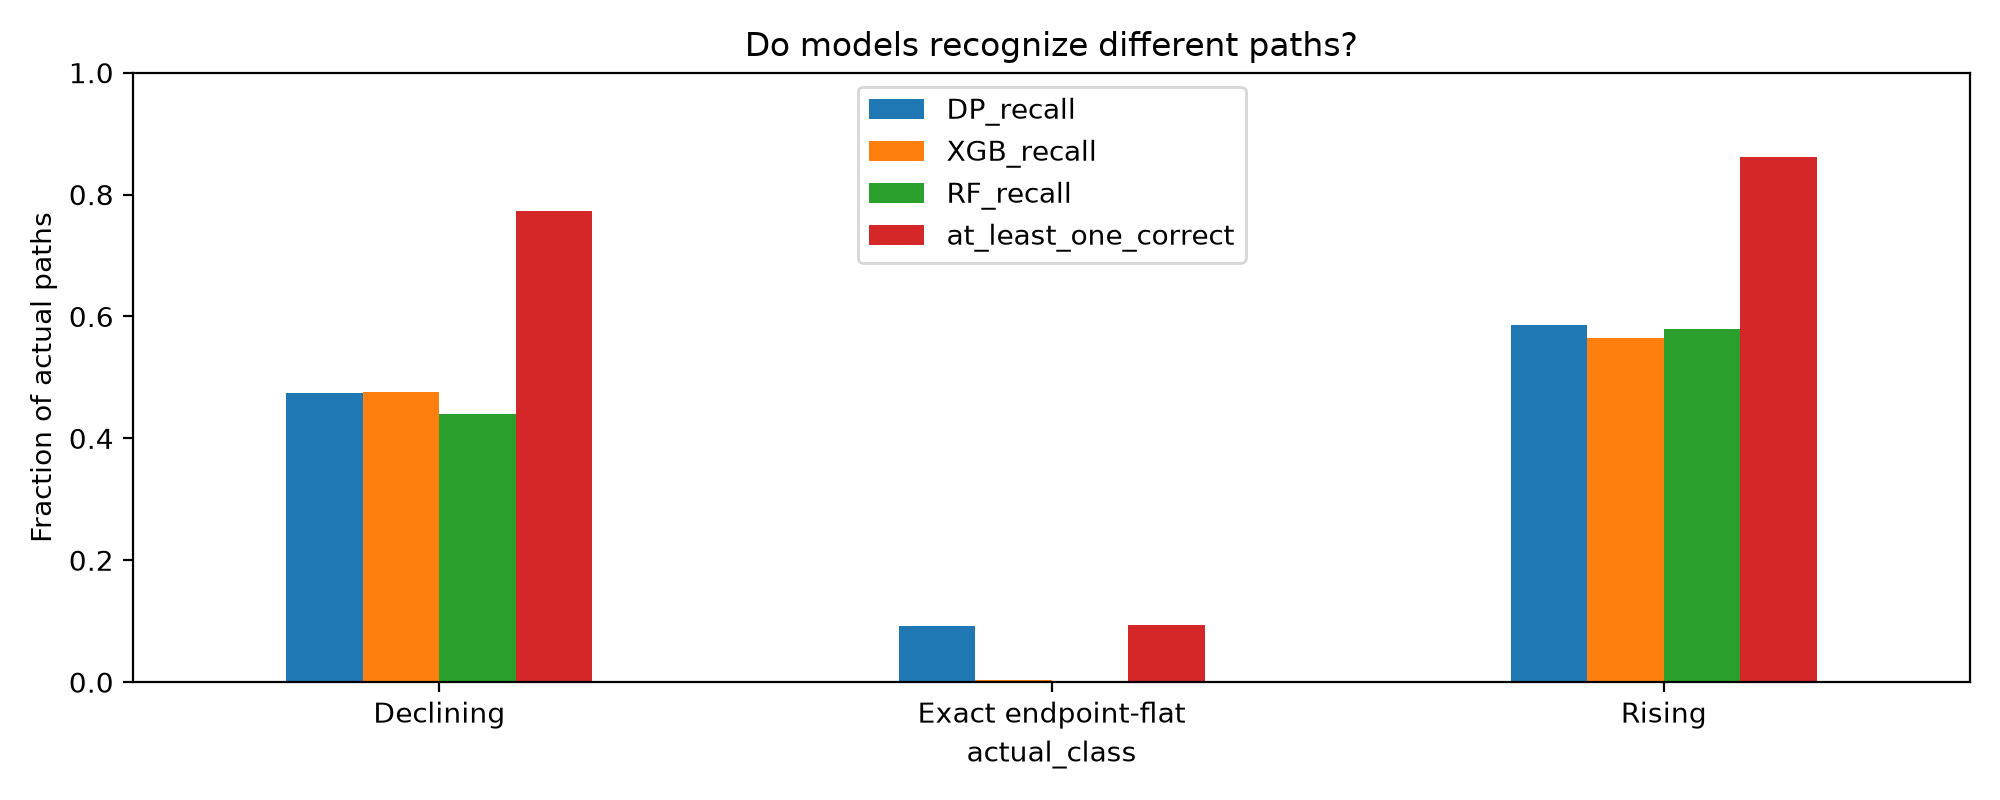

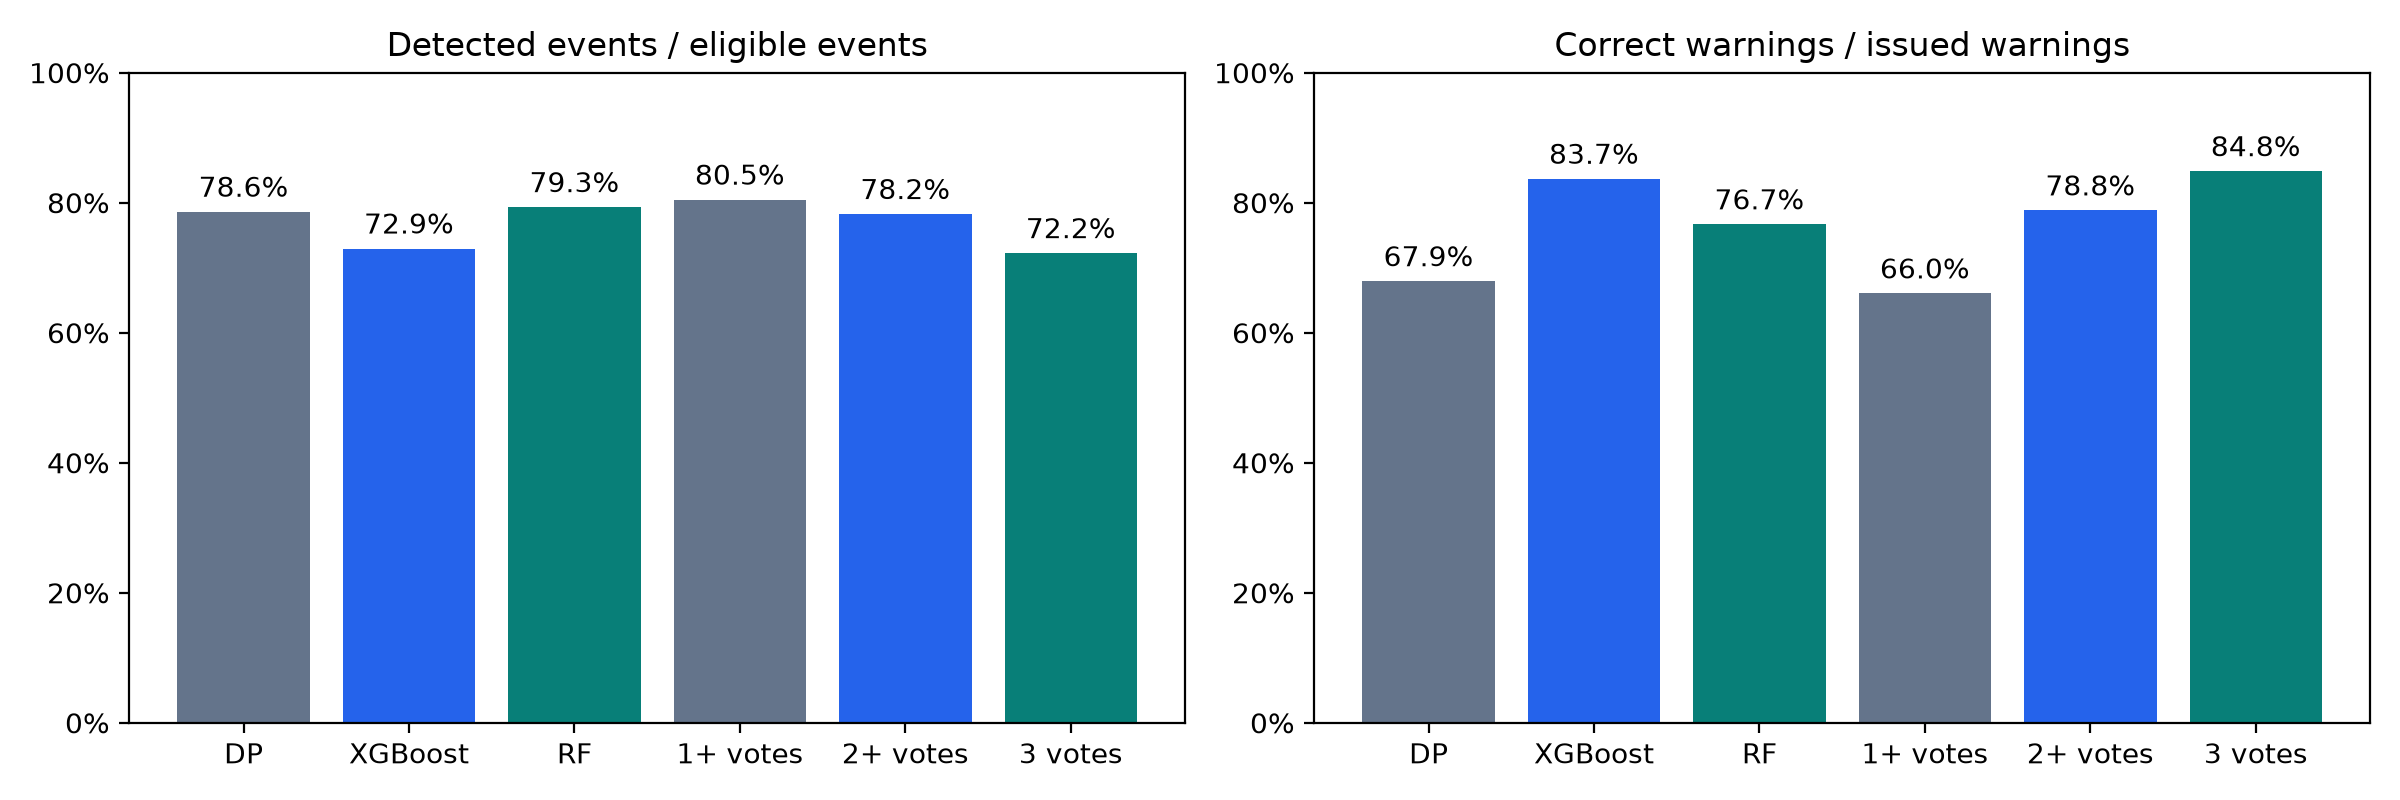

In [4]:
display(pd.read_csv(OUTPUT/'model_complementarity/direction_overlap_by_actual_class.csv').round(4))
display(pd.read_csv(OUTPUT/'model_complementarity/direction_vote_rules.csv').round(4))
from IPython.display import display,Image,Markdown
display(Image(filename=str(OUTPUT/'model_complementarity/direction_overlap.png')))
display(Image(filename=str(OUTPUT/'model_complementarity/warning_vote_comparison.png')))

## Interpretation
An at-least-one-correct fraction is a coverage diagnostic: we cannot know in advance which model is right. For actual use, evaluate explicit vote rules and their false positives. Direction votes for rise and decline are separate screening rules; at-least-one may flag both and is not a three-class classifier. More votes can improve precision at the cost of missed events. Existing thresholds are fixed; no threshold is selected on September–December. Event overlap uses individual matched events, while combined warning metrics recompute cooldown and matching from daily votes. These are different quantities.

In [5]:
display(Markdown((OUTPUT/'model_complementarity/RESULTS.md').read_text(encoding='utf-8')))

# Three-model complementarity

| actual_class        |   paths |   DP_recall |   XGB_recall |   RF_recall |   at_least_one_correct |   at_least_two_correct |   all_three_correct |   all_three_wrong |
|:--------------------|--------:|------------:|-------------:|------------:|-----------------------:|-----------------------:|--------------------:|------------------:|
| Declining           |   30267 |   0.474345  |   0.475964   |    0.440116 |              0.772425  |             0.452209   |            0.165791 |          0.227575 |
| Exact endpoint-flat |   80714 |   0.0918428 |   0.00377877 |    0        |              0.0937879 |             0.00183363 |            0        |          0.906212 |
| Rising              |   31174 |   0.585552  |   0.564862   |    0.579361 |              0.861808  |             0.597357   |            0.27061  |          0.138192 |

| rule                   |   events |   detected_events |   warning_episodes |   false_warning_episodes |   event_recall |   warning_precision |   false_warnings_per_30_at_risk_zip_days |   mean_lead_days |   median_lead_days |   at_risk_zip_days |
|:-----------------------|---------:|------------------:|-------------------:|-------------------------:|---------------:|--------------------:|-----------------------------------------:|-----------------:|-------------------:|-------------------:|
| Dynamic Panel FE       |     1131 |               889 |               1309 |                      420 |       0.78603  |            0.679144 |                                0.226859  |          1.30484 |                  1 |              55541 |
| XGBoost                |     1131 |               825 |                986 |                      161 |       0.729443 |            0.836714 |                                0.0869628 |          1.13576 |                  1 |              55541 |
| Random Forest          |     1131 |               897 |               1170 |                      273 |       0.793103 |            0.766667 |                                0.147459  |          1.23077 |                  1 |              55541 |
| At least 1 model votes |     1131 |               910 |               1378 |                      468 |       0.804598 |            0.660377 |                                0.252786  |          1.33516 |                  1 |              55541 |
| At least 2 model votes |     1131 |               885 |               1123 |                      238 |       0.782493 |            0.788068 |                                0.128554  |          1.20791 |                  1 |              55541 |
| At least 3 model votes |     1131 |               817 |                963 |                      146 |       0.72237  |            0.84839  |                                0.0788607 |          1.12362 |                  1 |              55541 |

Event overlap among original individual warning systems:

|   models_detecting |   events |     share |
|-------------------:|---------:|----------:|
|                  0 |      153 | 0.135279  |
|                  1 |       93 | 0.0822281 |
|                  2 |      137 | 0.121132  |
|                  3 |      748 | 0.661362  |

Union of correct paths is retrospective coverage, not attainable accuracy without knowing which model is correct. Voting rules are prospective functions of model outputs only. Votes are formed on the same ZIP-date BEFORE applying one shared cooldown and event matching, rather than unioning already-matched warnings. Individual thresholds are retained from original calibration; no new assessment tuning. This is exploratory 2020 analysis. Model votes are correlated; three votes do not constitute three independent pieces of evidence. The min/max model envelope is model disagreement, not a confidence or prediction interval.
